# Previsão do consumo combinado de combustível

Este projeto aborda a previsão do consumo combinado de combustível de um veículo a partir de suas características construtivas e de motorização.

O banco de dados foi obtido a partir do seguinte link:
https://www.fueleconomy.gov/feg/download.shtml

# Inspeção inicial do dataset de veículos

Este notebook apresenta a estrutura da base antes de decisões de limpeza. As análises exploratórias usam `df`, que permanece inalterado. Ao final, `df_model` é criado como uma cópia de trabalho com os veículos de 2010 a 2025, inclusive. O campo `comb08` é um candidato a alvo para uma etapa futura.

As células de código estão separadas por tipo de inspeção. Leia a observação antes de cada saída e anote dúvidas sobre valores especiais, como `-1`, em vez de tratá-los como erros imediatamente.

## Carregamento da base

O caminho é localizado a partir do diretório atual ou de seus diretórios pais, então o notebook pode ser executado com o diretório atual na raiz do projeto ou em `notebooks/`. `low_memory=False` pede ao pandas que infira os tipos considerando o arquivo inteiro; isso não remove linhas, preenche valores nem converte colunas manualmente.

In [46]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "data" / "raw" / "vehicles.csv").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei data/raw/vehicles.csv a partir do diretório atual.")

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "vehicles.csv"
df = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Arquivo: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"DataFrame carregado: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Arquivo: data/raw/vehicles.csv
DataFrame carregado: 50,407 linhas × 84 colunas


## Número de linhas e colunas

Linhas são registros de veículos e colunas são atributos registrados para cada veículo. O tamanho ajuda a dimensionar o trabalho e a interpretar contagens e estatísticas. Antes de treinar qualquer modelo, também será importante verificar se há registros repetidos ou observações que não representam veículos independentes.

In [47]:
linhas, colunas = df.shape
print(f"Linhas: {linhas:,}")
print(f"Colunas: {colunas}")

Linhas: 50,407
Colunas: 84


## Nomes das colunas

Use a lista para reconhecer os atributos disponíveis e localizar campos que podem ser relevantes em análises futuras, como `comb08`, ano, fabricante e combustível. Nomes parecidos podem representar medidas ou condições diferentes; confirme o significado antes de escolher variáveis para um modelo.

In [48]:
display(pd.Index(df.columns, name="coluna").to_frame(index=False))

,coluna
0,barrels08
1,barrelsA08
2,charge120
3,charge240
4,city08
...,...
79,modifiedOn
80,startStop
81,phevCity
82,phevHwy


## Tipos de dados

Tipos numéricos permitem cálculos; tipos `object`/texto costumam indicar categorias, identificadores ou valores mistos. Verifique especialmente campos que parecem datas ou números armazenados como texto. Tipos inesperados podem afetar resumos e análises futuras, mas esta inspeção não os converte.

In [49]:
display(df.dtypes.astype(str).rename("tipo").to_frame())

,tipo
barrels08,float64
barrelsA08,float64
charge120,float64
charge240,float64
city08,int64
...,...
modifiedOn,str
startStop,str
phevCity,int64
phevHwy,int64


## Informações gerais do DataFrame

`info()` resume quantidade de linhas, colunas, tipos, valores não nulos e memória aproximada. Compare os valores não nulos com o total de linhas para localizar possíveis ausências. Campos com tipos `object` merecem atenção se contiverem valores de formatos diferentes. Ausência no pandas não é a mesma coisa que um código sentinela como `-1`.

In [50]:
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 50407 entries, 0 to 50406
Data columns (total 84 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   barrels08        50407 non-null  float64
 1   barrelsA08       50407 non-null  float64
 2   charge120        50407 non-null  float64
 3   charge240        50407 non-null  float64
 4   city08           50407 non-null  int64  
 5   city08U          50407 non-null  float64
 6   cityA08          50407 non-null  int64  
 7   cityA08U         50407 non-null  float64
 8   cityCD           50407 non-null  float64
 9   cityE            50407 non-null  float64
 10  cityUF           50407 non-null  float64
 11  co2              50407 non-null  int64  
 12  co2A             50407 non-null  int64  
 13  co2TailpipeAGpm  50407 non-null  float64
 14  co2TailpipeGpm   50407 non-null  float64
 15  comb08           50407 non-null  int64  
 16  comb08U          50407 non-null  float64
 17  combA08          50407 

## Estatísticas descritivas das variáveis numéricas

`describe()` apresenta contagem, média, desvio-padrão, mínimo, quartis e máximo. A transposição coloca cada variável em uma linha para facilitar a comparação. Observe diferenças de escala, dispersão e valores extremos; mínimos como `-1` podem ser códigos especiais, não medidas reais. `describe()` resume apenas as colunas numéricas e não decide o que deve ser limpo.

In [51]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
barrels08,50407.0,14.838048,4.847023,0.047081,12.396250,14.8755,17.500588,42.501429
barrelsA08,50407.0,0.191641,0.984561,0.000000,0.000000,0.0000,0.000000,16.528333
charge120,50407.0,0.000063,0.014253,0.000000,0.000000,0.0000,0.000000,3.200000
charge240,50407.0,0.354740,1.896633,0.000000,0.000000,0.0000,0.000000,19.000000
city08,50407.0,21.068205,15.609411,6.000000,15.000000,18.0000,21.000000,153.000000
city08U,50407.0,10.960543,19.532638,0.000000,0.000000,0.0000,18.561100,155.824200
cityA08,50407.0,0.977106,7.246179,0.000000,0.000000,0.0000,0.000000,145.000000
cityA08U,50407.0,0.854756,7.179842,0.000000,0.000000,0.0000,0.000000,145.083500
cityCD,50407.0,0.000698,0.038652,0.000000,0.000000,0.0000,0.000000,5.350000
cityE,50407.0,1.655791,8.369548,0.000000,0.000000,0.0000,0.000000,122.000000


## Triagem de variáveis para prever `comb08`

`comb08` representa eficiência combinada em MPG: valores maiores significam mais milhas por galão, não maior consumo por distância. Esta é uma triagem inicial baseada no significado das colunas e na cobertura observada; ainda não é uma seleção final de atributos.

### Candidatos iniciais

| Grupo | Colunas | Evidência e uso esperado |
|---|---|---|
| Ano e classe | `year`, `VClass` | Têm 44 e 34 valores distintos, respectivamente, sem valores ausentes. Descrevem a geração e a categoria do veículo. |
| Combustível e configuração | `fuelType1`, `drive`, `trany` | Têm 7, 7 e 40 valores distintos. `drive` tem 2,4% ausentes; os outros dois não têm ausentes. Podem distinguir tecnologias e configurações. |
| Motor e porte | `cylinders`, `displ`, `hpv`, `pv2`, `pv4`, `lv2`, `lv4` | `cylinders` e `displ` têm 3,3% ausentes; os demais estão preenchidos. Representam características técnicas potencialmente úteis, mas valores como `-1` e `0` ainda precisam ser interpretados. |
| Fabricante e modelo | `make`, `model`, `baseModel` | Estão preenchidos, mas têm 146, 5.688 e 1.502 valores distintos. Podem ajudar, porém elevam a cardinalidade e podem fazer o modelo memorizar combinações conhecidas. Testar somente com validação que considere modelos/veículos não vistos. |

Como conjunto inicial para investigar, priorize `year`, `VClass`, `fuelType1`, `drive`, `trany`, `cylinders` e `displ`; depois compare a contribuição das medidas de porte/potência. `make`, `model` e `baseModel` devem ser avaliados à parte.

### Campos opcionais e cobertura

`startStop` tem 62,9% de valores ausentes; `tCharger`, 76,6%; `guzzler`, 94,3%; `sCharger`, 97,7%. Campos associados à eletrificação também são muito esparsos: `atvType` tem 86,4% ausentes, `evMotor` 92,8% e `fuelType2` 96,0%. Não descarte esses atributos automaticamente: primeiro investigue se a ausência significa “não aplicável” e se há um subgrupo de veículos para o qual eles são informativos.

### Evitar no primeiro modelo: possível vazamento

Não use `comb08` como preditor, pois é o alvo. Também deixe de fora, inicialmente, medidas que expressam ou derivam diretamente eficiência/consumo, como `city08`, `highway08`, `UCity`, `UHighway`, `comb08U`, `combA08`, `combE` e variantes. Neste arquivo, a correlação de Pearson com `comb08` é 0,996 para `city08`, 0,994 para `UCity`, 0,989 para `highway08`, 0,987 para `UHighway` e 0,852 para `comb08U`. Essa associação muito alta é um alerta, não uma prova isolada; junto ao significado dessas medidas, indica risco de o modelo receber informação que só existe depois do cálculo do consumo.

Avalie também com cautela `fuelCost08`, `barrels08`, `co2TailpipeGpm`, `feScore`, `ghgScore` e `youSaveSpend`: são métricas de custo, emissões ou eficiência que podem ser calculadas a partir de consumo/MPG. Não as inclua no baseline até confirmar que estariam disponíveis no momento real da previsão.

Esta etapa não remove colunas, linhas nem valores. Antes de fechar os preditores, investigue sentinelas, zeros e ausências; depois defina como representar categorias e como separar treino/teste, especialmente se o objetivo for prever modelos ainda não vistos.

## Avaliação de registros duplicados

Esta seção diferencia linhas integralmente repetidas de registros que compartilham apenas alguns atributos. `id` é um identificador, não uma prova suficiente de que os veículos sejam distintos. A chave descritiva `year`, `make`, `model`, `trany` e `drive` é apenas exploratória: combinações iguais podem corresponder a versões/configurações legítimas. Nenhuma linha será removida ou alterada.

In [52]:
mascara_duplicata_exata = df.duplicated(keep=False)
mascara_excedente_exato = df.duplicated(keep="first")
mascara_id_duplicado = df["id"].duplicated(keep=False)

colunas_sem_id = [coluna for coluna in df.columns if coluna != "id"]
mascara_sem_id = df.duplicated(subset=colunas_sem_id, keep=False)
mascara_excedente_sem_id = df.duplicated(subset=colunas_sem_id, keep="first")
grupos_exatos = df.loc[mascara_duplicata_exata].drop_duplicates().shape[0]
grupos_sem_id = df.loc[mascara_sem_id].drop_duplicates(subset=colunas_sem_id).shape[0]

resumo_duplicatas = pd.DataFrame(
    [
        {
            "verificacao": "Linha integralmente duplicada (todas as colunas)",
            "grupos_repetidos": int(grupos_exatos),
            "linhas_em_grupos_repetidos": int(mascara_duplicata_exata.sum()),
            "ocorrencias_alem_da_primeira": int(mascara_excedente_exato.sum()),
        },
        {
            "verificacao": "Linha repetida ignorando id",
            "grupos_repetidos": int(grupos_sem_id),
            "linhas_em_grupos_repetidos": int(mascara_sem_id.sum()),
            "ocorrencias_alem_da_primeira": int(mascara_excedente_sem_id.sum()),
        },
    ]
)
resumo_id = pd.DataFrame(
    {
        "medida": ["ids ausentes", "linhas com id repetido", "ids únicos"],
        "quantidade": [
            int(df["id"].isna().sum()),
            int(mascara_id_duplicado.sum()),
            int(df["id"].nunique()),
        ],
    }
)

display(resumo_duplicatas)
display(resumo_id)

,verificacao,grupos_repetidos,linhas_em_grupos_repetidos,ocorrencias_alem_da_primeira
0,Linha integralmente duplicada (todas as colunas),0,0,0
1,Linha repetida ignorando id,35,75,40


,medida,quantidade
0,ids ausentes,0
1,linhas com id repetido,0
2,ids únicos,50407


In [53]:
if mascara_sem_id.any():
    duplicatas_sem_id = (
        df.loc[mascara_sem_id]
        .sort_values(colunas_sem_id, kind="stable")
        .drop_duplicates(subset=colunas_sem_id, keep="first")
    )
    print("Exemplos de linhas iguais em todas as colunas, exceto id:")
    display(duplicatas_sem_id[["id", "year", "make", "model", "trany", "drive"]].head(10))
else:
    print("Não há linhas repetidas após desconsiderar id.")

chave_candidata = ["year", "make", "model", "trany", "drive"]
mascara_chave_repetida = df.duplicated(subset=chave_candidata, keep=False)
mascara_chave_excedente = df.duplicated(subset=chave_candidata, keep="first")
linhas_chaves_repetidas = df.loc[mascara_chave_repetida]
grupos_chave_repetida = linhas_chaves_repetidas.drop_duplicates(
    subset=chave_candidata
).shape[0]

print(
    f"Chave descritiva exploratória {chave_candidata}: "
    f"{int(mascara_chave_repetida.sum()):,} linhas em "
    f"{grupos_chave_repetida:,} combinações repetidas; "
    f"{int(mascara_chave_excedente.sum()):,} ocorrências além da primeira."
)

if mascara_chave_repetida.any():
    colunas_variacao = ["fuelType1", "cylinders", "displ", "VClass", "engId"]
    resumo_chaves = (
        linhas_chaves_repetidas.groupby(
            chave_candidata, dropna=False, observed=True, sort=False
        )
        .agg(
            registros=("id", "size"),
            combustiveis_distintos=("fuelType1", "nunique"),
            cilindradas_distintas=("displ", "nunique"),
            configuracoes_motor_distintas=("engId", "nunique"),
        )
        .sort_values(
            ["registros", "cilindradas_distintas", "configuracoes_motor_distintas"],
            ascending=False,
        )
    )
    display(resumo_chaves.head(15))

    chave_exemplo = resumo_chaves.index[0]
    mascara_exemplo = pd.Series(True, index=linhas_chaves_repetidas.index)
    for coluna, valor in zip(chave_candidata, chave_exemplo):
        if pd.isna(valor):
            mascara_exemplo &= linhas_chaves_repetidas[coluna].isna()
        else:
            mascara_exemplo &= linhas_chaves_repetidas[coluna].eq(valor)
    display(
        linhas_chaves_repetidas.loc[
            mascara_exemplo,
            chave_candidata + ["id"] + colunas_variacao,
        ]
    )

Exemplos de linhas iguais em todas as colunas, exceto id:


,id,year,make,model,trany,drive
4653,14187,1998,Chrysler,Sebring,Manual 5-spd,Front-Wheel Drive
4528,14074,1998,Eagle,Talon,Manual 5-spd,Front-Wheel Drive
47813,7664,1991,Mitsubishi,Mirage,Manual 5-spd,Front-Wheel Drive
47811,7662,1991,Mitsubishi,Mirage,Automatic 4-spd,Front-Wheel Drive
4651,14185,1998,Chrysler,Sebring,Automatic 4-spd,Front-Wheel Drive
4671,14202,1998,Dodge,Avenger,Automatic 4-spd,Front-Wheel Drive
7511,1676,1985,Subaru,Sedan 4WD,Automatic 3-spd,4-Wheel or All-Wheel Drive
4529,14075,1998,Eagle,Talon,Manual 5-spd,4-Wheel or All-Wheel Drive
4675,14206,1998,Dodge,Avenger,Automatic 4-spd,Front-Wheel Drive
4521,14068,1998,Eagle,Talon,Automatic 4-spd,Front-Wheel Drive


Chave descritiva exploratória ['year', 'make', 'model', 'trany', 'drive']: 22,787 linhas em 9,294 combinações repetidas; 13,493 ocorrências além da primeira.


registros  \
year make                       model                trany            drive                                   
1984 Volkswagen                 Jetta                Manual 5-spd     NaN                                10   
2022 Chevrolet                  Silverado 4WD        Automatic 10-spd 4-Wheel Drive                      10   
1985 Dodge                      D100/D150 Pickup 2WD Manual 4-spd     Rear-Wheel Drive                    9   
1984 Ford                       Escort               Manual 5-spd     NaN                                 9   
     Mercury                    Lynx                 Manual 5-spd     NaN                                 9   
1995 Dabryan Coach Builders Inc WB                   Automatic 4-spd  Rear-Wheel Drive                    9   
1985 Ford                       Escort               Manual 5-spd     Front-Wheel Drive                   8   
                                F150 Pickup 4WD      Manual 4-spd     4-Wheel or All-Wheel Drive          8   
1984 Dodge                      Ram 50 Pickup 2WD    Manual 5-spd     2-Wheel Drive                       8   
     Mitsubishi                 Truck 2WD            Manual 5-spd     2-Wheel Drive                       8   
     Chevrolet                  C10 Pickup 2WD       Manual 4-spd     2-Wheel Drive                       8   
     GMC                        C15 Pickup 2WD       Manual 4-spd     2-Wheel Drive                       8   
     Ford                       F150 Pickup 4WD      Manual 4-spd     4-Wheel or All-Wheel Drive          8   
                                Bronco 4WD           Manual 4-spd     4-Wheel or All-Wheel Drive          8   
2022 GMC                        Sierra 4WD           Automatic 10-spd 4-Wheel Drive                       8   

                                                                                                  combustiveis_distintos  \
year make                       model                trany            drive                                                
1984 Volkswagen                 Jetta                Manual 5-spd     NaN                                              2   
2022 Chevrolet                  Silverado 4WD        Automatic 10-spd 4-Wheel Drive                                    3   
1985 Dodge                      D100/D150 Pickup 2WD Manual 4-spd     Rear-Wheel Drive                                 1   
1984 Ford                       Escort               Manual 5-spd     NaN                                              2   
     Mercury                    Lynx                 Manual 5-spd     NaN                                              2   
1995 Dabryan Coach Builders Inc WB                   Automatic 4-spd  Rear-Wheel Drive                                 1   
1985 Ford                       Escort               Manual 5-spd     Front-Wheel Drive                                2   
                                F150 Pickup 4WD      Manual 4-spd     4-Wheel or All-Wheel Drive                       1   
1984 Dodge                      Ram 50 Pickup 2WD    Manual 5-spd     2-Wheel Drive                                    2   
     Mitsubishi                 Truck 2WD            Manual 5-spd     2-Wheel Drive                                    2   
     Chevrolet                  C10 Pickup 2WD       Manual 4-spd     2-Wheel Drive                                    2   
     GMC                        C15 Pickup 2WD       Manual 4-spd     2-Wheel Drive                                    2   
     Ford                       F150 Pickup 4WD      Manual 4-spd     4-Wheel or All-Wheel Drive                       1   
                                Bronco 4WD           Manual 4-spd     4-Wheel or All-Wheel Drive                       1   
2022 GMC                        Sierra 4WD           Automatic 10-spd 4-Wheel Drive                                    3   

                                                                                                  cil

,year,make,model,trany,drive,id,fuelType1,cylinders,displ,VClass,engId
18454,1984,Volkswagen,Jetta,Manual 5-spd,NaN,26778,Diesel,4.0,1.6,Subcompact Cars,59022
18455,1984,Volkswagen,Jetta,Manual 5-spd,NaN,26779,Diesel,4.0,1.6,Subcompact Cars,59023
18459,1984,Volkswagen,Jetta,Manual 5-spd,NaN,26782,Regular Gasoline,4.0,1.7,Subcompact Cars,59040
18460,1984,Volkswagen,Jetta,Manual 5-spd,NaN,26783,Regular Gasoline,4.0,1.7,Subcompact Cars,59041
18461,1984,Volkswagen,Jetta,Manual 5-spd,NaN,26784,Regular Gasoline,4.0,1.8,Subcompact Cars,59060
19671,1984,Volkswagen,Jetta,Manual 5-spd,NaN,27873,Diesel,4.0,1.6,Subcompact Cars,59028
19672,1984,Volkswagen,Jetta,Manual 5-spd,NaN,27874,Diesel,4.0,1.6,Subcompact Cars,59029
19675,1984,Volkswagen,Jetta,Manual 5-spd,NaN,27877,Regular Gasoline,4.0,1.7,Subcompact Cars,59045
19676,1984,Volkswagen,Jetta,Manual 5-spd,NaN,27878,Regular Gasoline,4.0,1.7,Subcompact Cars,59046
19677,1984,Volkswagen,Jetta,Manual 5-spd,NaN,27879,Regular Gasoline,4.0,1.8,Subcompact Cars,59065


### Interpretação

`linhas_em_grupos_repetidos` conta todas as linhas pertencentes a grupos repetidos; `ocorrencias_alem_da_primeira` conta quantas linhas excedem uma ocorrência por grupo. Repetições na chave exploratória não são duplicatas exatas: diferenças de motor, combustível ou versão podem representar veículos distintos. Examine as colunas discriminantes e a documentação da fonte antes de decidir qualquer deduplicação. Esta análise é somente diagnóstica.

## Categorias de combustível

Antes de restringir a análise, vamos comparar os três campos relacionados a combustível. `fuelType` descreve a categoria/rótulo geral e inclui combinações como gasolina com E85; `fuelType1` identifica o combustível principal em categorias mais padronizadas; `fuelType2` registra o combustível secundário quando aplicável e tem muitos valores ausentes. As colunas não são intercambiáveis. A tabela inclui ausentes explicitamente; o gráfico mostra todas as categorias observadas em `fuelType`. Nenhum filtro ou alteração é aplicado ao DataFrame.

In [54]:
colunas_combustivel = ["fuelType", "fuelType1", "fuelType2"]
linhas_frequencia_combustivel = []

for coluna in colunas_combustivel:
    frequencias = df[coluna].value_counts(dropna=False)
    total_preenchido = int(df[coluna].notna().sum())
    for categoria, quantidade in frequencias.items():
        ausente = bool(pd.isna(categoria))
        linhas_frequencia_combustivel.append(
            {
                "coluna": coluna,
                "categoria": "(ausente)" if ausente else str(categoria),
                "quantidade": int(quantidade),
                "% do total": quantidade / len(df) * 100,
                "% entre preenchidos": (
                    quantidade / total_preenchido * 100 if not ausente else float("nan")
                ),
            }
        )

frequencias_combustivel = pd.DataFrame(linhas_frequencia_combustivel)
display(
    frequencias_combustivel.style.format(
        {"% do total": "{:.2f}%", "% entre preenchidos": "{:.2f}%"}
    )
)

,coluna,categoria,quantidade,% do total,% entre preenchidos
0,fuelType,Regular,29816,59.15%,59.15%
1,fuelType,Premium,15374,30.50%,30.50%
2,fuelType,Electricity,1608,3.19%,3.19%
3,fuelType,Gasoline or E85,1410,2.80%,2.80%
4,fuelType,Diesel,1318,2.61%,2.61%
5,fuelType,Premium and Electricity,256,0.51%,0.51%
6,fuelType,Midgrade,174,0.35%,0.35%
7,fuelType,Regular Gas and Electricity,132,0.26%,0.26%
8,fuelType,Premium or E85,128,0.25%,0.25%
9,fuelType,CNG,60,0.12%,0.12%


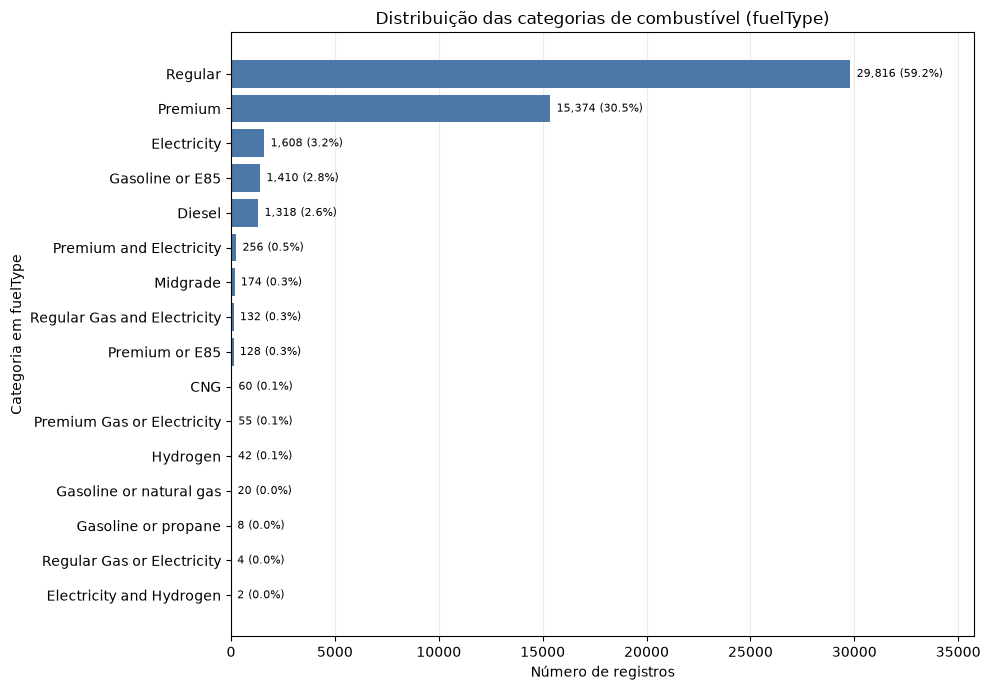

In [55]:
import matplotlib.pyplot as plt

frequencias_fuel_type = df["fuelType"].value_counts().sort_values()
percentuais_fuel_type = frequencias_fuel_type / len(df) * 100
fig, ax = plt.subplots(figsize=(10, 7))
barras = ax.barh(frequencias_fuel_type.index, frequencias_fuel_type.values, color="#4c78a8")
limite_x = frequencias_fuel_type.max()
for barra, quantidade, percentual in zip(
    barras, frequencias_fuel_type.values, percentuais_fuel_type.values
):
    ax.text(
        quantidade + limite_x * 0.01,
        barra.get_y() + barra.get_height() / 2,
        f"{quantidade:,} ({percentual:.1f}%)",
        va="center",
        fontsize=8,
    )
ax.set_xlim(0, limite_x * 1.2)
ax.set_xlabel("Número de registros")
ax.set_ylabel("Categoria em fuelType")
ax.set_title("Distribuição das categorias de combustível (fuelType)")
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Interpretação inicial

`fuelType` contém 16 rótulos observados: os mais frequentes são `Regular` (29.816 registros), `Premium` (15.374), `Electricity` (1.608), `Gasoline or E85` (1.410) e `Diesel` (1.318). Há também rótulos de combustível combinado, como `Premium and Electricity`, `Gasoline or natural gas` e `Gasoline or propane`. `fuelType1` possui 7 categorias observadas e 2 ausências; `fuelType2` possui 4 categorias e 48.394 ausências. Esses últimos ausentes não devem ser tratados como uma quinta categoria real de combustível sem verificar o significado de domínio.

O gráfico e as tabelas descrevem todos os registros carregados. Nenhum tipo de combustível foi filtrado ou removido; qualquer restrição deve ser uma decisão posterior, guiada pelo objetivo da análise.

## Distribuição dos registros por ano

A coluna `year` representa o ano associado ao veículo na base. A tabela apresenta mínimo, máximo e total de registros para cada ano observado; o gráfico mostra a frequência em ordem cronológica. Todos os registros são considerados, sem filtros ou alterações.

In [56]:
ano_minimo = int(df["year"].min())
ano_maximo = int(df["year"].max())
registros_por_ano = df["year"].value_counts().sort_index().rename("veiculos")
tabela_anos = registros_por_ano.to_frame()
tabela_anos["percentual"] = tabela_anos["veiculos"] / len(df) * 100

print(f"Ano mínimo: {ano_minimo}")
print(f"Ano máximo: {ano_maximo}")
print(f"Anos distintos: {registros_por_ano.size}")
print(f"Registros sem ano: {int(df['year'].isna().sum())}")
display(tabela_anos.style.format({"veiculos": "{:,.0f}", "percentual": "{:.2f}%"}))

Ano mínimo: 1984
Ano máximo: 2027
Anos distintos: 44
Registros sem ano: 0


,veiculos,percentual
year,,
1984,"1,964",3.90%
1985,"1,701",3.37%
1986,"1,210",2.40%
1987,"1,247",2.47%
1988,"1,130",2.24%
1989,"1,153",2.29%
1990,"1,078",2.14%
1991,"1,132",2.25%
1992,"1,121",2.22%


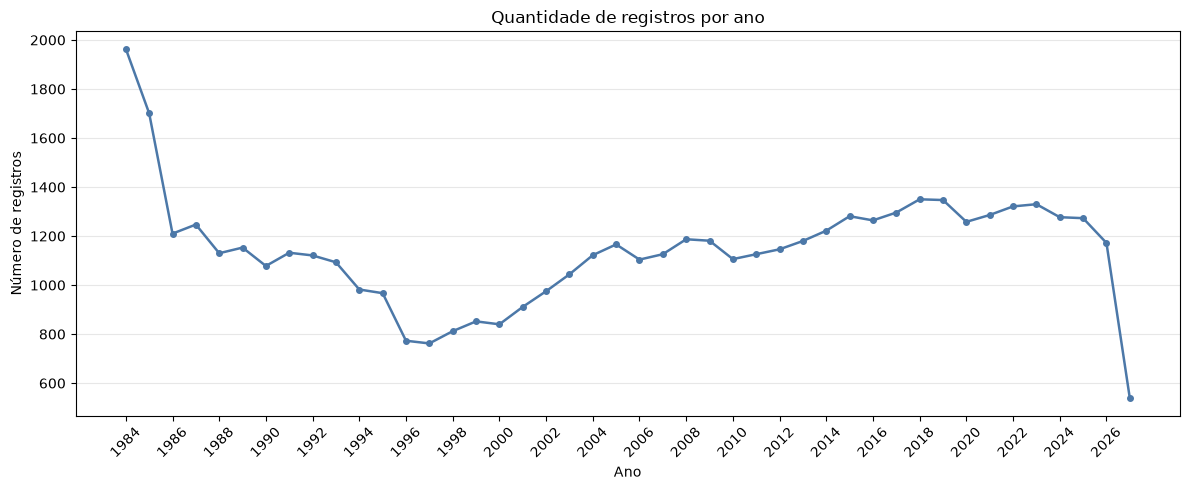

In [57]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(
    registros_por_ano.index,
    registros_por_ano.values,
    marker="o",
    markersize=4,
    linewidth=1.8,
    color="#4c78a8",
)
ax.set_title("Quantidade de registros por ano")
ax.set_xlabel("Ano")
ax.set_ylabel("Número de registros")
ax.set_xticks(registros_por_ano.index[::2])
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Interpretação

Na versão atual da base há registros de 1984 a 2027, distribuídos por 44 anos, sem valores ausentes em `year`. A contagem anual é uma contagem de linhas/veículos no arquivo, não necessariamente de veículos únicos no mundo real. Diferenças entre anos descrevem a composição desta base e, sem informações adicionais, não permitem concluir por que o volume varia.

## DataFrame de trabalho para modelagem

As análises anteriores usam `df` sem alterá-lo. A célula seguinte cria `df_model` como uma cópia independente contendo somente os veículos dos anos de 2010 a 2025, inclusive; a seleção deixa o dataset original intacto.

In [58]:
df_shape_antes = df.shape
df_model = df.loc[df["year"].between(2010, 2025)].copy()

assert df.shape == df_shape_antes, "A criação de df_model não deve modificar df."
assert df_model["year"].between(2010, 2025).all(), "df_model contém ano fora do intervalo."

print(f"df original: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print(f"df_model: {df_model.shape[0]:,} linhas × {df_model.shape[1]} colunas")
print(f"Anos em df_model: {df_model['year'].min()}–{df_model['year'].max()}")

df original: 50,407 linhas × 84 colunas
df_model: 20,063 linhas × 84 colunas
Anos em df_model: 2010–2025


## Análise exploratória da variável alvo `comb08`

`comb08` representa a eficiência combinada em milhas por galão (MPG). Valores maiores significam que o veículo percorre mais milhas por galão; não significam maior consumo por distância. A análise abaixo considera os registros de `df_model` (anos de 2010 a 2025), mantém todos os valores como estão e não treina nenhum modelo.

Registros válidos: 20,063 de 20,063
Valores ausentes em comb08: 0


,Valor
Média (MPG),26.73
Mediana (MPG),22.00
Mínimo (MPG),9.00
Máximo (MPG),146.00
Desvio padrão amostral (MPG),17.83
1º quartil (MPG),19.00
3º quartil (MPG),27.00
Assimetria,3.58


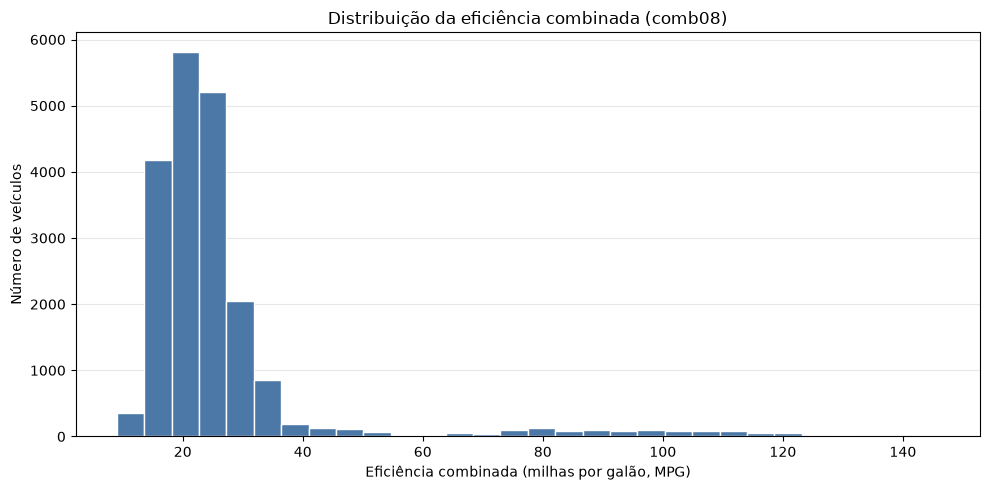

In [59]:
comb08 = df_model["comb08"].dropna()
ausentes_comb08 = int(df_model["comb08"].isna().sum())

estatisticas_comb08 = pd.Series(
    {
        "Média (MPG)": comb08.mean(),
        "Mediana (MPG)": comb08.median(),
        "Mínimo (MPG)": comb08.min(),
        "Máximo (MPG)": comb08.max(),
        "Desvio padrão amostral (MPG)": comb08.std(),
        "1º quartil (MPG)": comb08.quantile(0.25),
        "3º quartil (MPG)": comb08.quantile(0.75),
        "Assimetria": comb08.skew(),
    },
    name="Valor",
)

print(f"Registros válidos: {comb08.count():,} de {len(df_model):,}")
print(f"Valores ausentes em comb08: {ausentes_comb08:,}")
display(estatisticas_comb08.to_frame().style.format("{:,.2f}"))

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(comb08, bins=30, color="#4c78a8", edgecolor="white")
ax.set_title("Distribuição da eficiência combinada (comb08)")
ax.set_xlabel("Eficiência combinada (milhas por galão, MPG)")
ax.set_ylabel("Número de veículos")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Como interpretar as estatísticas

- **Média:** soma dos valores dividida pelo número de veículos válidos; resume o nível médio de MPG, mas pode ser puxada por valores extremos.
- **Mediana:** valor central após ordenar os veículos; metade tem `comb08` menor ou igual a ela e metade maior ou igual. É menos sensível a extremos do que a média.
- **Mínimo e máximo:** menor e maior valores observados. Definem a amplitude registrada, mas extremos devem ser interpretados no contexto dos tipos de veículos e da medição.
- **Desvio padrão amostral:** indica o quanto os valores tendem a se afastar da média, na mesma unidade (MPG). Um valor maior corresponde a maior dispersão; não é o erro do modelo.
- **Quartis e assimetria:** os quartis delimitam a metade central dos dados; a assimetria resume o desequilíbrio da distribuição (positiva indica uma cauda mais longa à direita, negativa à esquerda). São complementos para ler o histograma.

### Leitura da distribuição

No histograma, cada barra mostra quantos veículos caem em uma faixa de MPG. Observe onde se concentra a maior parte dos registros, a largura da distribuição e a presença de caudas ou grupos separados. A média acima da mediana junto com assimetria positiva é compatível com uma cauda à direita; a comparação deve ser feita com o formato visual e não identifica, por si só, a causa. Nenhum valor foi excluído ou transformado para gerar esse gráfico.

## Relação entre cilindrada (`displ`) e eficiência (`comb08`)

O gráfico abaixo explora os veículos de `df_model` (anos de 2010 a 2025). Cada ponto representa um veículo; `displ` está no eixo X, em litros, e `comb08` no eixo Y, em milhas por galão (MPG). Apenas para desenhar o gráfico, são usados os registros com ambas as medidas observadas: nenhuma linha é removida de `df_model` nem qualquer valor é imputado. As correlações de Pearson e Spearman são apresentadas como resumos de associação, não são linhas de ajuste nem modelos.

Pares válidos plotados: 18,931 de 20,063
Registros sem displ ou comb08, não plotados: 1,132
Correlação de Pearson: -0.733
Correlação de Spearman: -0.859


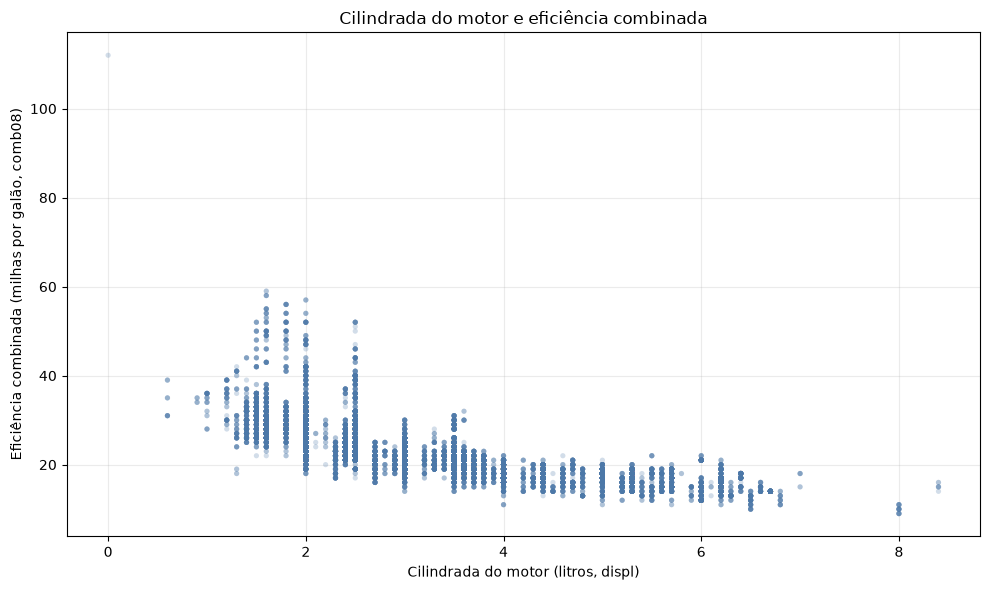

In [60]:
pares_displ_comb08 = df_model[["displ", "comb08"]].dropna()
pares_ausentes = len(df_model) - len(pares_displ_comb08)

print(f"Pares válidos plotados: {len(pares_displ_comb08):,} de {len(df_model):,}")
print(f"Registros sem displ ou comb08, não plotados: {pares_ausentes:,}")
print(
    "Correlação de Pearson: "
    f"{pares_displ_comb08['displ'].corr(pares_displ_comb08['comb08']):.3f}"
)
print(
    "Correlação de Spearman: "
    f"{pares_displ_comb08['displ'].corr(pares_displ_comb08['comb08'], method='spearman'):.3f}"
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    pares_displ_comb08["displ"],
    pares_displ_comb08["comb08"],
    alpha=0.25,
    s=14,
    color="#4c78a8",
    edgecolors="none",
)
ax.set_title("Cilindrada do motor e eficiência combinada")
ax.set_xlabel("Cilindrada do motor (litros, displ)")
ax.set_ylabel("Eficiência combinada (milhas por galão, comb08)")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Como interpretar

- **Tendência:** observe se a nuvem geral sobe ou desce à medida que `displ` aumenta. Uma tendência descendente significa que motores de maior cilindrada tendem a estar associados a menor eficiência (MPG) nesta amostra; associação não prova causalidade.
- **Dispersão:** a variação vertical dos pontos para uma mesma cilindrada indica que `displ`, sozinho, não determina `comb08`; outros atributos dos veículos também podem estar associados à eficiência.
- **Linearidade:** uma faixa aproximadamente reta sugere relação visualmente linear. Curvatura, mudanças de inclinação ou agrupamentos sugerem que uma reta simples não descreve bem toda a nuvem. Pearson resume associação linear; Spearman resume associação monotônica baseada em postos. A diferença entre eles pode alertar para não linearidade, mas não substitui a inspeção do gráfico.
- **Pontos extremos:** pontos isolados, sobretudo longe da nuvem principal, são candidatos a observações atípicas e merecem consulta às características do veículo e à documentação. Não os remova apenas por parecerem extremos.

Esta etapa é apenas exploratória: não há regressão, linha de tendência nem treinamento de modelo.

## Eficiência combinada (`comb08`) por número de cilindros

A tabela e o gráfico usam `df_model` (veículos dos anos 2010 a 2025). Primeiro, listamos os valores observados em `cylinders` e a quantidade de veículos em cada grupo. Os registros sem número de cilindros são contados à parte; não serão tratados como um grupo de cilindros conhecido na comparação das médias. `comb08` é eficiência em milhas por galão (MPG), então média maior significa maior eficiência, não maior consumo por distância.

In [61]:
cilindros_ausentes = int(df_model["cylinders"].isna().sum())
comb08_ausentes_cilindros = int(df_model["comb08"].isna().sum())

resumo_cilindros = (
    df_model.loc[df_model["cylinders"].notna()]
    .groupby("cylinders")
    .agg(
        veiculos=("cylinders", "size"),
        comb08_validos=("comb08", "count"),
        comb08_medio=("comb08", "mean"),
        comb08_desvio_padrao=("comb08", "std"),
    )
    .sort_index()
)

print(f"Veículos em df_model: {len(df_model):,}")
print(f"Veículos sem número de cilindros: {cilindros_ausentes:,}")
print(f"Valores ausentes em comb08: {comb08_ausentes_cilindros:,}")
print("Contagem por número de cilindros observado:")
display(resumo_cilindros[["veiculos", "comb08_validos"]])
print("Média e desvio padrão de comb08 por grupo:")
display(
    resumo_cilindros[["comb08_medio", "comb08_desvio_padrao"]].style.format("{:,.2f}")
)

Veículos em df_model: 20,063
Veículos sem número de cilindros: 1,133
Valores ausentes em comb08: 0
Contagem por número de cilindros observado:


,veiculos,comb08_validos
cylinders,,
2.0,16,16
3.0,263,263
4.0,7916,7916
5.0,144,144
6.0,6282,6282
8.0,3756,3756
10.0,117,117
12.0,416,416
16.0,20,20


Média e desvio padrão de comb08 por grupo:


,comb08_medio,comb08_desvio_padrao
cylinders,,
2.000000,30.12,7.54
3.000000,30.88,3.60
4.000000,27.36,5.70
5.000000,22.35,3.06
6.000000,20.91,2.49
8.000000,16.85,1.98
10.000000,15.07,1.45
12.000000,13.97,1.48
16.000000,10.00,0.79


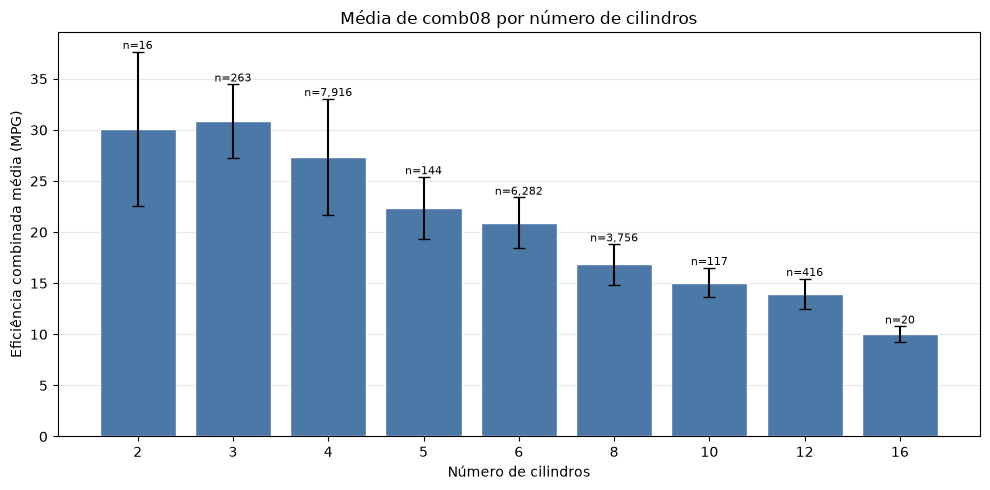

In [62]:
fig, ax = plt.subplots(figsize=(10, 5))
barras_cilindros = ax.bar(
    resumo_cilindros.index.astype(int).astype(str),
    resumo_cilindros["comb08_medio"],
    yerr=resumo_cilindros["comb08_desvio_padrao"],
    capsize=4,
    color="#4c78a8",
    edgecolor="white",
)

for barra, (_, grupo) in zip(barras_cilindros, resumo_cilindros.iterrows()):
    ax.annotate(
        f"n={int(grupo['veiculos']):,}",
        (barra.get_x() + barra.get_width() / 2, barra.get_height() + grupo["comb08_desvio_padrao"]),
        ha="center",
        va="bottom",
        fontsize=8,
    )

ax.set_title("Média de comb08 por número de cilindros")
ax.set_xlabel("Número de cilindros")
ax.set_ylabel("Eficiência combinada média (MPG)")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### Interpretação

A altura de cada barra representa a média de `comb08` para aquele número de cilindros. As barras de erro mostram um desvio padrão para cada lado da média; não são intervalos de confiança. O rótulo `n` informa quantos veículos compõem o grupo, importante porque médias de grupos pequenos são menos estáveis e as barras de erro também refletem a variação dentro do grupo.

Na amostra, os números observados são 2, 3, 4, 5, 6, 8, 10, 12 e 16 cilindros. Os grupos mais numerosos são 4 cilindros (7.916 veículos), 6 cilindros (6.282) e 8 cilindros (3.756); há 1.133 veículos sem `cylinders` informado. As médias tendem a cair de aproximadamente 30,9 MPG (3 cilindros) para 10,0 MPG (16 cilindros), mas os grupos de 2, 3, 5, 10 e 16 cilindros têm bem menos observações, e as médias não demonstram causalidade. Como a ausência de cilindros pode estar associada a motores elétricos, a média desse grupo não é comparável a uma categoria de cilindros e foi deixada fora do gráfico.

## `comb08` por categoria de veículo (`VClass`)

A tabela a seguir resume os veículos de `df_model` (anos de 2010 a 2025) por categoria `VClass`, com a quantidade de veículos e a média de eficiência combinada (`comb08`) em MPG. `comb08` mede milhas por galão; uma média maior indica maior eficiência, não maior consumo por distância. Os valores ausentes de categoria, se houver, são exibidos separadamente.

In [63]:
resumo_vclass = (
    df_model.groupby("VClass", dropna=False, sort=True)
    .agg(
        veiculos=("VClass", "size"),
        comb08_validos=("comb08", "count"),
        comb08_medio=("comb08", "mean"),
    )
)

print(f"Veículos em df_model: {len(df_model):,}")
print(f"Categorias observadas de VClass: {df_model['VClass'].nunique(dropna=True)}")
print(f"Veículos sem categoria VClass: {int(df_model['VClass'].isna().sum()):,}")
print(f"Valores ausentes em comb08: {int(df_model['comb08'].isna().sum()):,}")
display(
    resumo_vclass.rename(
        columns={
            "veiculos": "Quantidade de veículos",
            "comb08_validos": "comb08 válido",
            "comb08_medio": "Média de comb08 (MPG)",
        }
    ).style.format({"Média de comb08 (MPG)": "{:,.2f}"})
)

Veículos em df_model: 20,063
Categorias observadas de VClass: 24
Veículos sem categoria VClass: 0
Valores ausentes em comb08: 0


,Quantidade de veículos,comb08 válido,Média de comb08 (MPG)
VClass,,,
Compact Cars,2389,2389,28.89
Large Cars,1575,1575,29.63
Midsize Cars,2781,2781,30.67
Midsize Station Wagons,125,125,23.61
Minicompact Cars,824,824,23.36
Minivan - 2WD,155,155,22.50
Minivan - 4WD,23,23,25.48
Small Pickup Trucks 2WD,233,233,20.60
Small Pickup Trucks 4WD,224,224,19.06


## Transmissão (`trany`): frequências e cardinalidade

A análise usa `df_model` (veículos dos anos de 2010 a 2025). Primeiro contamos as categorias exatamente como aparecem na base, sem juntar descrições nem modificar valores. A tabela exibe as 15 mais frequentes; a quantidade total de categorias e de valores ausentes também é informada.

In [64]:
frequencias_trany = df_model["trany"].value_counts(dropna=False)
top_trany = frequencias_trany.head(15).rename_axis("Descrição original de trany").to_frame("Veículos")
top_trany["Percentual"] = top_trany["Veículos"] / len(df_model) * 100

print(f"Veículos em df_model: {len(df_model):,}")
print(f"Categorias distintas de trany (sem ausentes): {df_model['trany'].nunique()}")
print(f"Valores ausentes em trany: {int(df_model['trany'].isna().sum()):,}")
print(f"Cobertura acumulada das 15 categorias mais frequentes: {top_trany['Veículos'].sum() / len(df_model):.1%}")
display(top_trany.style.format({"Veículos": "{:,.0f}", "Percentual": "{:.2f}%"}))

Veículos em df_model: 20,063
Categorias distintas de trany (sem ausentes): 34
Valores ausentes em trany: 0
Cobertura acumulada das 15 categorias mais frequentes: 84.8%


,Veículos,Percentual
Descrição original de trany,,
Automatic (S8),"3,359",16.74%
Automatic (S6),"2,602",12.97%
Manual 6-spd,"1,951",9.72%
Automatic 6-spd,"1,416",7.06%
Automatic 8-spd,"1,053",5.25%
Automatic (A1),"1,053",5.25%
Automatic (variable gear ratios),899,4.48%
Automatic (AM-S7),816,4.07%
Automatic 9-spd,812,4.05%


### Leitura e recomendação

Há 34 categorias distintas, portanto `trany` tem cardinalidade moderada: há mais descrições do que em uma variável binária, mas não são tantas a ponto de justificar uma etapa manual de agrupamento neste momento. As descrições preservam informação útil sobre tipo de transmissão e número/configuração de marchas. As categorias mais comuns incluem `Automatic (S8)` (3.359 veículos), `Automatic (S6)` (2.602), `Manual 6-spd` (1.951), `Automatic 6-spd` (1.416) e `Automatic 8-spd` e `Automatic (A1)` (1.053 cada). Não há valores ausentes neste recorte.

**Alternativa mais simples:** manter `trany` com as descrições originais durante a análise e, quando montarmos o pipeline de modelagem, aplicar `OneHotEncoder` às variáveis categóricas. Não agrupar categorias manualmente agora: isso exigiria regras adicionais e poderia descartar diferenças entre transmissões. Na etapa de modelagem, ajuste o encoder somente nos dados de treino e configure tratamento para categorias desconhecidas na validação/uso futuro (por exemplo, `handle_unknown="ignore"`). O encoder ainda criará várias colunas binárias, mas 34 categorias são uma dimensão razoável para começar; depois, a validação poderá mostrar se alguma simplificação é necessária.

Neste passo, nenhum valor foi recodificado e nenhum modelo foi treinado.

## Correlações entre variáveis numéricas

Para manter a leitura objetiva, a matriz inclui `comb08`, `displ`, `cylinders`, `year` e `co2TailpipeGpm`. `city08` e `highway08` ficam de fora por serem medidas diretamente relacionadas ao consumo combinado, evitando redundância na interpretação do alvo. A matriz de Pearson resume associações lineares; cada par usa somente linhas válidas para as duas variáveis. `cylinders` é discreta, embora seja tratada numericamente nesta exploração. Correlação não implica causalidade, e associações não lineares podem não ser bem resumidas por Pearson. Nenhum modelo será treinado.

Veículos no recorte: 20,063
Quantidade de pares válidos em cada correlação com comb08:


,Pares válidos
comb08,20063
displ,18931
cylinders,18930
year,20063
co2TailpipeGpm,20063


Matriz de correlação de Pearson:


,comb08,displ,cylinders,year,co2TailpipeGpm
comb08,1.00,-0.73,-0.71,0.26,-0.83
displ,-0.73,1.00,0.92,-0.11,0.82
cylinders,-0.71,0.92,1.00,-0.08,0.80
year,0.26,-0.11,-0.08,1.00,-0.27
co2TailpipeGpm,-0.83,0.82,0.80,-0.27,1.00


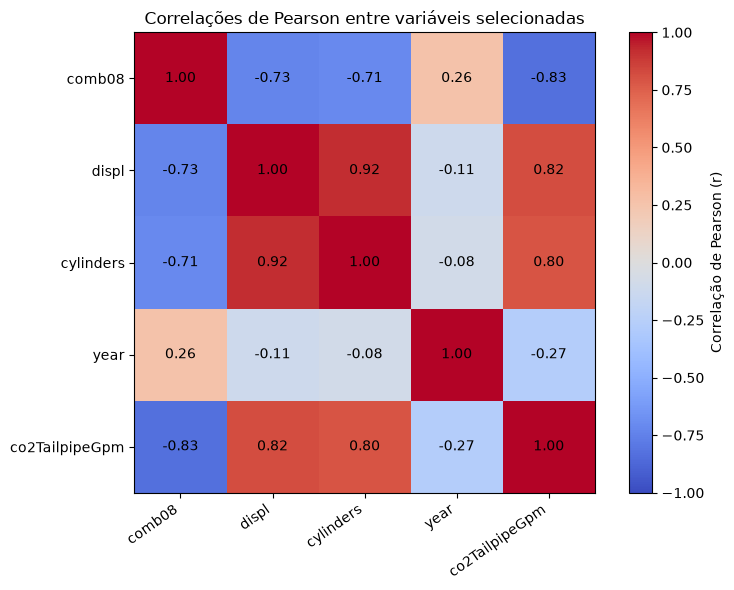


Relações lineares com comb08:
displ: relação negativa muito forte (r = -0.733).
cylinders: relação negativa muito forte (r = -0.707).
year: relação positiva fraca (r = 0.262).
co2TailpipeGpm: relação negativa muito forte (r = -0.833).


In [65]:
import pandas as pd
import matplotlib.pyplot as plt

variaveis_correlacao = ["comb08", "displ", "cylinders", "year", "co2TailpipeGpm"]
dados_correlacao = df_model.loc[:, variaveis_correlacao].apply(pd.to_numeric, errors="coerce")
matriz_correlacao = dados_correlacao.corr(method="pearson", min_periods=2)
mascara_validos = dados_correlacao.notna().astype("int64")
contagens_pares = mascara_validos.T.dot(mascara_validos)

print(f"Veículos no recorte: {len(df_model):,}")
print("Quantidade de pares válidos em cada correlação com comb08:")
display(contagens_pares.loc["comb08", variaveis_correlacao].rename("Pares válidos").to_frame())
print("Matriz de correlação de Pearson:")
display(matriz_correlacao.style.format("{:.2f}").background_gradient(cmap="coolwarm", vmin=-1, vmax=1))

fig, ax = plt.subplots(figsize=(8, 6))
imagem = ax.imshow(matriz_correlacao, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(variaveis_correlacao)), labels=variaveis_correlacao, rotation=35, ha="right")
ax.set_yticks(range(len(variaveis_correlacao)), labels=variaveis_correlacao)
for linha in range(len(variaveis_correlacao)):
    for coluna in range(len(variaveis_correlacao)):
        valor = matriz_correlacao.iloc[linha, coluna]
        ax.text(coluna, linha, "NA" if pd.isna(valor) else f"{valor:.2f}", ha="center", va="center")
ax.set_title("Correlações de Pearson entre variáveis selecionadas")
fig.colorbar(imagem, ax=ax, label="Correlação de Pearson (r)")
fig.tight_layout()
plt.show()

def classificar_correlacao(valor):
    intensidade = abs(valor)
    if intensidade < 0.10:
        return "próxima de nula"
    if intensidade < 0.30:
        return "fraca"
    if intensidade < 0.50:
        return "moderada"
    if intensidade < 0.70:
        return "forte"
    return "muito forte"

print("\nRelações lineares com comb08:")
for variavel, valor in matriz_correlacao["comb08"].drop("comb08").items():
    if pd.isna(valor):
        print(f"{variavel}: não foi possível calcular a correlação.")
        continue
    sentido = "positiva" if valor > 0 else "negativa" if valor < 0 else "nula"
    print(f"{variavel}: relação {sentido} {classificar_correlacao(valor)} (r = {valor:.3f}).")

## Seleção das variáveis para o primeiro modelo

O alvo escolhido é `comb08` (MPG combinado). No recorte `df_model` (modelos dos anos de 2010 a 2025), há 20.063 veículos e nenhum valor ausente no alvo. As candidatas foram avaliadas antes de construir `X` e `y`:

- **`year` — manter.** Não tem valores ausentes e apresenta correlação de Pearson positiva fraca com `comb08` (`r = 0,262`). O ano pode capturar mudanças de eficiência ao longo do tempo. A avaliação posterior deverá considerar uma validação temporal se o objetivo for prever anos futuros.
- **`displ` — manter.** Cilindrada é uma medida numérica relevante e tem correlação negativa forte com `comb08` (`r = -0,733`). Há 1.132 valores ausentes (5,6%); serão tratados numa etapa de pré-processamento, sem remover linhas nesta seleção inicial.
- **`cylinders` — não incluir no primeiro conjunto.** Também se relaciona fortemente com o alvo (`r = -0,707`), mas é muito redundante com `displ` (correlação entre ambas `r = 0,92`) e tem praticamente a mesma quantidade de ausências (1.133). Para um primeiro modelo, mantenho `displ`, que oferece medida contínua mais granular, e retiro `cylinders` para reduzir multicolinearidade. A variável poderá ser comparada em modelos posteriores.
- **`trany` — manter.** A transmissão não tem valores ausentes e possui 34 categorias. Tipo e número de marchas podem informar eficiência; será necessário codificá-la como categórica no pré-processamento. Frequências baixas poderão exigir atenção ao validar o modelo.
- **`drive` — manter.** Não tem valores ausentes e contém 6 categorias observadas, descrevendo a configuração de tração. É uma variável categórica pequena e potencialmente explicativa.
- **`vclass` — manter como `VClass`.** A coluna da base tem essa capitalização, 24 categorias e nenhum valor ausente. A classe do veículo pode explicar diferenças de tamanho e finalidade; a codificação categórica fica para o pré-processamento.
- **`fueltype1` — manter como `fuelType1`.** A coluna contém 8 níveis incluindo um valor ausente. O tipo de combustível pode ser importante para a eficiência; o único ausente deve ser tratado explicitamente no pré-processamento, sem descartar a observação agora.

`city08` e `highway08` **não serão usados**: são medidas de eficiência em ciclo urbano e rodoviário que compõem diretamente a medida combinada `comb08`, de modo que incluí-las permitiria ao modelo reconstruir o alvo a partir de seus componentes (vazamento do alvo). A matriz exploratória também mostra `co2TailpipeGpm`, mas esse campo não está entre as candidatas definidas para este primeiro conjunto.

In [66]:
features = ["year", "displ", "trany", "drive", "VClass", "fuelType1"]
target = "comb08"

colunas_necessarias = [target, *features]
colunas_ausentes = [coluna for coluna in colunas_necessarias if coluna not in df_model.columns]
if colunas_ausentes:
    raise KeyError(f"Colunas necessárias não encontradas em df_model: {colunas_ausentes}")

X = df_model.loc[:, features].copy()
y = df_model.loc[:, target].copy()

assert X.index.equals(y.index), "X e y devem preservar os mesmos índices e a mesma ordem."
assert not {"city08", "highway08", "cylinders"}.intersection(X.columns)

print(f"X: {X.shape[0]:,} veículos × {X.shape[1]} features")
print(f"y: {y.shape[0]:,} valores de {target}")
print(f"Features: {list(X.columns)}")
print("Valores ausentes por feature:")
display(X.isna().sum().rename("Valores ausentes").to_frame())
print(f"Valores ausentes em y: {y.isna().sum()}")

X: 20,063 veículos × 6 features
y: 20,063 valores de comb08
Features: ['year', 'displ', 'trany', 'drive', 'VClass', 'fuelType1']
Valores ausentes por feature:


,Valores ausentes
year,0
displ,1132
trany,0
drive,0
VClass,0
fuelType1,1


Valores ausentes em y: 0


## Divisão em treino e teste

A divisão separa os dados usados para ajustar o modelo (`treino`) daqueles reservados para avaliar seu desempenho em dados não usados no ajuste (`teste`). `test_size=0.2` reserva 20% para teste e deixa 80% para treino. Por padrão, `train_test_split` embaralha os dados (`shuffle=True`). `random_state=42` define a semente aleatória para tornar a divisão reproduzível com os mesmos dados e na mesma ordem.

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

X_train: (16050, 6)
X_test: (4013, 6)
y_train: (16050,)
y_test: (4013,)


## Pré-processamento das features

As etapas a seguir preenchem valores ausentes e convertem as colunas categóricas em indicadores one-hot. O pré-processador será ajustado apenas em `X_train`; nenhuma etapa de modelagem será criada.

In [68]:
import numpy as np
from scipy import sparse
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [69]:
colunas_numericas = ["year", "displ"]
colunas_categoricas = ["trany", "drive", "VClass", "fuelType1"]

In [70]:
transformador_numerico = SimpleImputer(strategy="median")

In [71]:
transformador_categorico = Pipeline(
    steps=[
        ("imputador", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

In [72]:
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", transformador_numerico, colunas_numericas),
        ("categoricas", transformador_categorico, colunas_categoricas),
    ]
)

Ajustamos as regras de imputação e as categorias do encoder no treino. No teste, apenas aplicamos as regras já aprendidas, evitando vazamento de informação.

In [73]:
X_train_preprocessado = preprocessador.fit_transform(X_train)
X_test_preprocessado = preprocessador.transform(X_test)

print(f"X_train_preprocessado: {X_train_preprocessado.shape}")
print(f"X_test_preprocessado: {X_test_preprocessado.shape}")

X_train_preprocessado: (16050, 73)
X_test_preprocessado: (4013, 73)


In [74]:
def possui_valores_ausentes(matriz):
    valores = matriz.data if sparse.issparse(matriz) else matriz
    return bool(np.isnan(valores).any())


print(
    "Ausentes após o pré-processamento — "
    f"treino: {possui_valores_ausentes(X_train_preprocessado)}, "
    f"teste: {possui_valores_ausentes(X_test_preprocessado)}"
)

Ausentes após o pré-processamento — treino: False, teste: False


## Primeiro baseline: regressão linear

O pipeline combina o pré-processamento e `LinearRegression`, para que as mesmas transformações ajustadas no treino também sejam aplicadas automaticamente ao teste.

In [75]:
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

pipeline_baseline = Pipeline(
    steps=[
        ("preprocessador", clone(preprocessador)),
        ("regressor", LinearRegression()),
    ]
)

In [76]:
pipeline_baseline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessador', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['year','displ','trany','drive','VClass','fuelType1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categoricas', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columns

In [77]:
y_test_pred = pipeline_baseline.predict(X_test)

print(f"Dimensão das previsões: {y_test_pred.shape}")
print("Primeiras 10 previsões:")
print(y_test_pred[:10])

Dimensão das previsões: (4013,)
Primeiras 10 previsões:
[23.33770403 26.78757481 26.00206571 31.1102576  21.83042836 96.20381829
 13.00073524 23.55176117 18.12072496 20.41457769]


## Avaliação da regressão linear

Calculamos as métricas no conjunto de teste, comparando `y_test` com `y_test_pred`:

- **MAE (Mean Absolute Error):** erro absoluto médio entre valores reais e previstos. É fácil de interpretar e está na mesma unidade do alvo (`comb08`, MPG); quanto menor, melhor.
- **RMSE (Root Mean Squared Error):** raiz do erro quadrático médio, também em MPG. Penaliza mais fortemente erros grandes, sendo útil para perceber previsões muito distantes; quanto menor, melhor.
- **R² (coeficiente de determinação):** compara o erro do modelo com a referência de prever a média de `y_test`. Valores mais próximos de 1 indicam maior variabilidade explicada; 0 equivale à referência da média e valores negativos indicam desempenho pior que essa referência.

In [78]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_test_pred)
rmse = root_mean_squared_error(y_test, y_test_pred)
r2 = r2_score(y_test, y_test_pred)

print(f"MAE:  {mae:.3f} MPG")
print(f"RMSE: {rmse:.3f} MPG")
print(f"R²:   {r2:.3f}")

MAE:  2.757 MPG
RMSE: 4.858 MPG
R²:   0.927


## DecisionTreeRegressor: primeiro modelo de árvore

Usamos as mesmas partições de treino e teste do baseline linear. A profundidade máxima de 5 mantém a árvore simples neste experimento inicial; `random_state=42` torna o ajuste reproduzível. O pré-processamento é ajustado dentro do pipeline usando somente o treino.

In [79]:
from sklearn.tree import DecisionTreeRegressor

pipeline_arvore = Pipeline(
    steps=[
        ("preprocessador", clone(preprocessador)),
        ("regressor", DecisionTreeRegressor(max_depth=5, random_state=42)),
    ]
)

In [80]:
_ = pipeline_arvore.fit(X_train, y_train)

In [81]:
y_test_pred_arvore = pipeline_arvore.predict(X_test)

print(f"Dimensão das previsões da árvore: {y_test_pred_arvore.shape}")

Dimensão das previsões da árvore: (4013,)


In [82]:
mae_arvore = mean_absolute_error(y_test, y_test_pred_arvore)
rmse_arvore = root_mean_squared_error(y_test, y_test_pred_arvore)
r2_arvore = r2_score(y_test, y_test_pred_arvore)

comparacao_modelos = pd.DataFrame(
    {
        "MAE (MPG)": [mae, mae_arvore],
        "RMSE (MPG)": [rmse, rmse_arvore],
        "R²": [r2, r2_arvore],
    },
    index=["Regressão linear", "DecisionTreeRegressor (max_depth=5)"],
)

print(comparacao_modelos.round(3).to_string())

                                     MAE (MPG)  RMSE (MPG)     R²
Regressão linear                         2.757       4.858  0.927
DecisionTreeRegressor (max_depth=5)      2.740       4.525  0.936


## RandomForestRegressor

Esta etapa reutiliza exatamente `X_train`, `y_train` e `X_test` da divisão anterior. O pré-processamento é ajustado dentro do pipeline somente com os dados de treino. Usamos 100 árvores e `random_state=42`, mantendo os demais parâmetros padrão.

In [83]:
from sklearn.ensemble import RandomForestRegressor

pipeline_random_forest = Pipeline(
    steps=[
        ("preprocessador", clone(preprocessador)),
        ("regressor", RandomForestRegressor(n_estimators=100, random_state=42)),
    ]
)

In [84]:
_ = pipeline_random_forest.fit(X_train, y_train)

In [85]:
y_test_pred_random_forest = pipeline_random_forest.predict(X_test)

print(f"Dimensão das previsões: {y_test_pred_random_forest.shape}")

Dimensão das previsões: (4013,)


In [86]:
mae_random_forest = mean_absolute_error(y_test, y_test_pred_random_forest)
rmse_random_forest = root_mean_squared_error(y_test, y_test_pred_random_forest)
r2_random_forest = r2_score(y_test, y_test_pred_random_forest)

print(f"MAE:  {mae_random_forest:.3f} MPG")
print(f"RMSE: {rmse_random_forest:.3f} MPG")
print(f"R²:   {r2_random_forest:.3f}")

MAE:  1.406 MPG
RMSE: 3.215 MPG
R²:   0.968


## Comparação consolidada dos modelos

A tabela e o gráfico abaixo comparam as três métricas no mesmo conjunto de teste. MAE e RMSE são erros em MPG e devem ser minimizados; R² é adimensional e deve ser maximizado. Por isso, os erros e o R² são apresentados em painéis separados.

In [88]:
comparacao_final = pd.DataFrame(
    {
        "modelo": [
            "Regressão linear",
            "DecisionTreeRegressor",
            "RandomForestRegressor",
        ],
        "MAE": [mae, mae_arvore, mae_random_forest],
        "RMSE": [rmse, rmse_arvore, rmse_random_forest],
        "R²": [r2, r2_arvore, r2_random_forest],
    }
)

print(comparacao_final.round(3).to_string(index=False))

               modelo   MAE  RMSE    R²
     Regressão linear 2.757 4.858 0.927
DecisionTreeRegressor 2.740 4.525 0.936
RandomForestRegressor 1.406 3.215 0.968


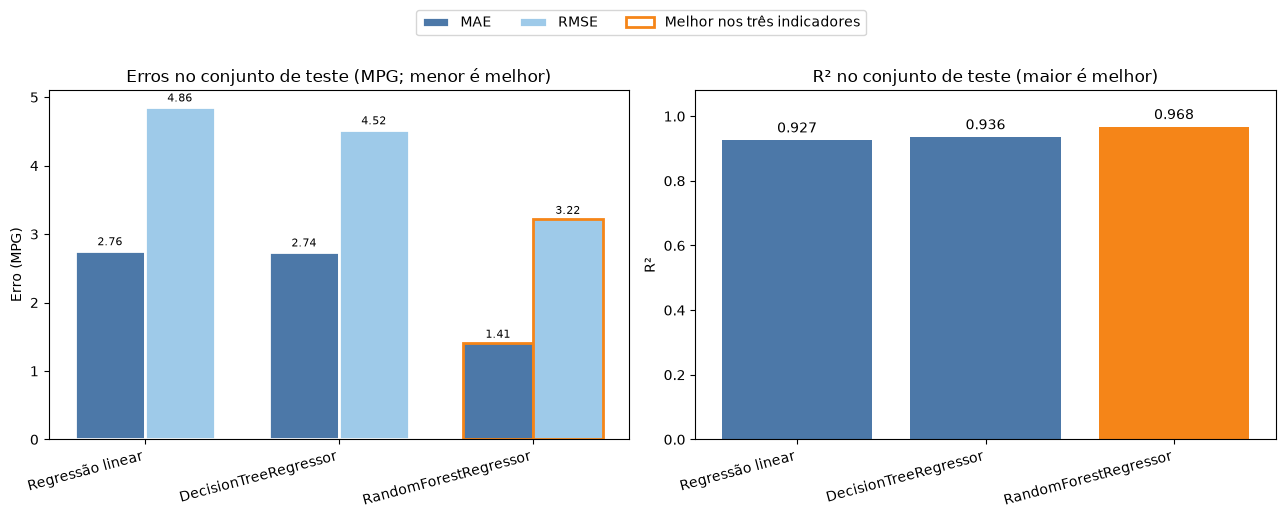

Melhor desempenho conjunto: RandomForestRegressor. Ele tem o menor MAE (1.406 MPG), o menor RMSE (3.215 MPG) e o maior R² (0.968) nesta divisão de teste.


In [89]:
melhor_por_metrica = {
    "MAE": comparacao_final.loc[comparacao_final["MAE"].idxmin(), "modelo"],
    "RMSE": comparacao_final.loc[comparacao_final["RMSE"].idxmin(), "modelo"],
    "R²": comparacao_final.loc[comparacao_final["R²"].idxmax(), "modelo"],
}
modelos_vencedores = set(melhor_por_metrica.values())
melhor_modelo = next(iter(modelos_vencedores)) if len(modelos_vencedores) == 1 else None

from matplotlib.patches import Patch

fig, (ax_erros, ax_r2) = plt.subplots(1, 2, figsize=(13, 5))
posicoes = np.arange(len(comparacao_final))
largura = 0.36
contornos = ["#f58518" if modelo == melhor_modelo else "#ffffff" for modelo in comparacao_final["modelo"]]

barras_mae = ax_erros.bar(
    posicoes - largura / 2, comparacao_final["MAE"], largura,
    label="MAE", color="#4c78a8", edgecolor=contornos, linewidth=2,
)
barras_rmse = ax_erros.bar(
    posicoes + largura / 2, comparacao_final["RMSE"], largura,
    label="RMSE", color="#9ecae9", edgecolor=contornos, linewidth=2,
)
ax_erros.set_title("Erros no conjunto de teste (MPG; menor é melhor)")
ax_erros.set_ylabel("Erro (MPG)")
ax_erros.set_xticks(posicoes, labels=comparacao_final["modelo"], rotation=15, ha="right")
ax_erros.bar_label(barras_mae, fmt="%.2f", padding=2, fontsize=8)
ax_erros.bar_label(barras_rmse, fmt="%.2f", padding=2, fontsize=8)

cores_r2 = ["#f58518" if modelo == melhor_modelo else "#4c78a8" for modelo in comparacao_final["modelo"]]
barras_r2 = ax_r2.bar(posicoes, comparacao_final["R²"], color=cores_r2)
ax_r2.set_title("R² no conjunto de teste (maior é melhor)")
ax_r2.set_ylabel("R²")
ax_r2.set_ylim(0, 1.08)
ax_r2.set_xticks(posicoes, labels=comparacao_final["modelo"], rotation=15, ha="right")
ax_r2.bar_label(barras_r2, fmt="%.3f", padding=3)
fig.legend(
    handles=[
        barras_mae,
        barras_rmse,
        Patch(facecolor="white", edgecolor="#f58518", linewidth=2, label="Melhor nos três indicadores"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.04),
    ncol=3,
)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

if melhor_modelo is not None:
    print(
        f"Melhor desempenho conjunto: {melhor_modelo}. "
        f"Ele tem o menor MAE ({comparacao_final['MAE'].min():.3f} MPG), "
        f"o menor RMSE ({comparacao_final['RMSE'].min():.3f} MPG) "
        f"e o maior R² ({comparacao_final['R²'].max():.3f}) nesta divisão de teste."
    )
else:
    print(f"Melhores por métrica: {melhor_por_metrica}. Há um compromisso entre as métricas nesta divisão de teste.")

## Análise dos resíduos do melhor modelo

Um **resíduo** é a diferença entre o valor real e o valor previsto: `resíduo = valor real - valor previsto`. Resíduo positivo significa que o modelo subestimou o valor real; resíduo negativo significa que o superestimou. Aqui analisamos as previsões do `RandomForestRegressor` no conjunto de teste, o melhor modelo na comparação anterior.

Idealmente, os resíduos ficam aproximadamente centrados em zero e sem padrão claro em relação aos valores previstos. Um deslocamento geral em relação a zero pode indicar viés; assimetria ou caudas longas podem indicar erros mais frequentes/grandes em uma direção; pontos extremos podem revelar casos difíceis ou problemas nos dados. Curvas ou outras estruturas no gráfico resíduos versus previstos podem indicar relações não capturadas, e um formato de funil pode sugerir variância dos erros não constante. Agrupamentos podem refletir subgrupos de veículos. Esses sinais orientam investigações, mas não provam isoladamente que o modelo está inadequado; árvores também podem gerar bandas por repetirem valores previstos.

Nesta avaliação, a média dos resíduos é próxima de zero (0,039 MPG), e a distribuição tem forte concentração central, mas também caudas e observações extremas. No gráfico resíduos versus previstos, a dispersão parece aumentar para previsões mais altas (especialmente acima de aproximadamente 80 MPG), com alguns resíduos bem distantes de zero. Isso pode indicar que o erro varia conforme a faixa prevista e merece investigação; não é, por si só, prova de inadequação do modelo.

In [90]:
residuos_random_forest = y_test - y_test_pred_random_forest

print(f"Resíduos calculados para {len(residuos_random_forest):,} observações de teste.")
print(f"Média dos resíduos: {residuos_random_forest.mean():.3f} MPG")

Resíduos calculados para 4,013 observações de teste.
Média dos resíduos: 0.039 MPG


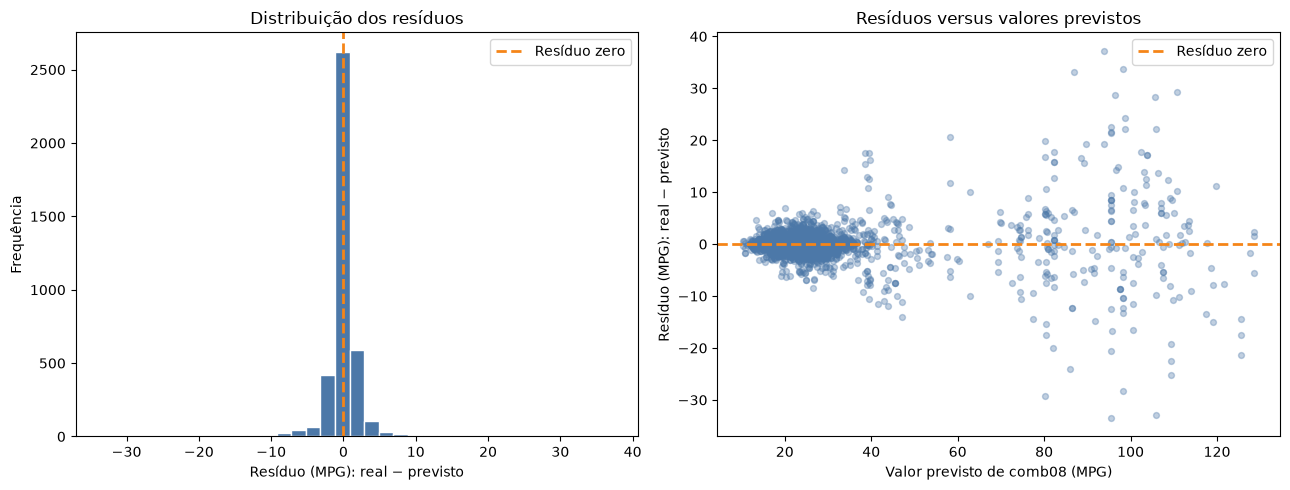

In [91]:
fig, (ax_distribuicao, ax_previstos) = plt.subplots(1, 2, figsize=(13, 5))

ax_distribuicao.hist(residuos_random_forest, bins=35, color="#4c78a8", edgecolor="white")
ax_distribuicao.axvline(0, color="#f58518", linestyle="--", linewidth=2, label="Resíduo zero")
ax_distribuicao.set_title("Distribuição dos resíduos")
ax_distribuicao.set_xlabel("Resíduo (MPG): real − previsto")
ax_distribuicao.set_ylabel("Frequência")
ax_distribuicao.legend()

ax_previstos.scatter(y_test_pred_random_forest, residuos_random_forest, alpha=0.35, color="#4c78a8", s=18)
ax_previstos.axhline(0, color="#f58518", linestyle="--", linewidth=2, label="Resíduo zero")
ax_previstos.set_title("Resíduos versus valores previstos")
ax_previstos.set_xlabel("Valor previsto de comb08 (MPG)")
ax_previstos.set_ylabel("Resíduo (MPG): real − previsto")
ax_previstos.legend()

fig.tight_layout()
plt.show()

## 15 features mais importantes do Random Forest

As importâncias por redução média de impureza são associadas aos nomes de saída do pré-processador ajustado, incluindo cada categoria criada pelo `OneHotEncoder`. A tabela é ordenada da maior para a menor importância; o gráfico destaca as 15 primeiras. A importância descreve o uso das features pelo modelo, mas não demonstra causalidade.

,feature,importancia
0,categoricas__fuelType1_Electricity,8.380049e-01
1,numericas__displ,7.058556e-02
2,categoricas__fuelType1_Hydrogen,1.213466e-02
3,numericas__year,1.137012e-02
4,categoricas__VClass_Standard Sport Utility Veh...,7.953126e-03
...,...,...
68,categoricas__trany_Automatic (S4),3.784827e-06
69,categoricas__trany_Automatic (AM5),3.635123e-06
70,categoricas__fuelType1_Natural Gas,1.752768e-06
71,categoricas__drive_4-Wheel or All-Wheel Drive,5.355298e-07


Gráfico salvo em: outputs/figures/random_forest_top_15_importancias.png


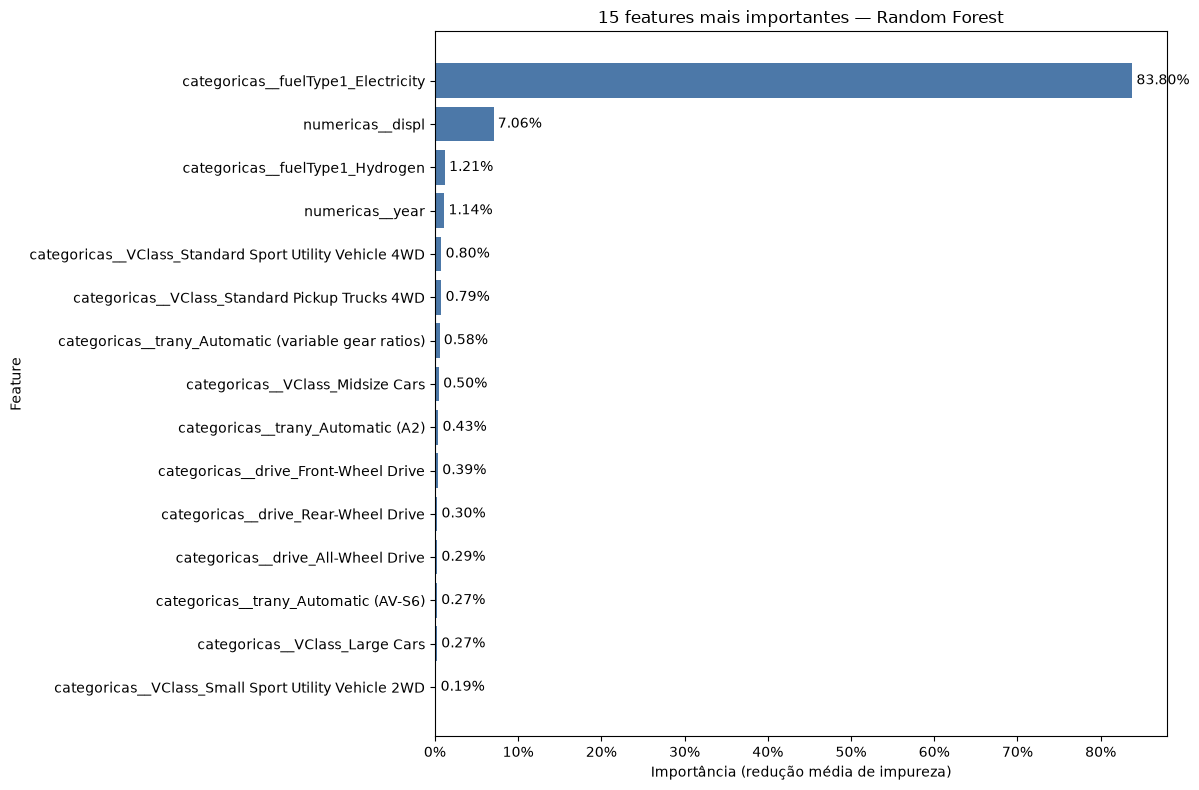

In [87]:
from matplotlib.ticker import PercentFormatter

preprocessador_random_forest = pipeline_random_forest.named_steps["preprocessador"]
modelo_random_forest = pipeline_random_forest.named_steps["regressor"]
nomes_features_random_forest = preprocessador_random_forest.get_feature_names_out()
importancias_random_forest = modelo_random_forest.feature_importances_

if len(nomes_features_random_forest) != len(importancias_random_forest):
    raise ValueError("A quantidade de nomes de features não corresponde às importâncias do Random Forest.")

importancias_features_random_forest = (
    pd.DataFrame(
        {
            "feature": nomes_features_random_forest,
            "importancia": importancias_random_forest,
        }
    )
    .sort_values("importancia", ascending=False)
    .reset_index(drop=True)
)

display(importancias_features_random_forest)

top_15_features_random_forest = importancias_features_random_forest.head(15)
fig, ax = plt.subplots(figsize=(12, 8))
barras_importancia = ax.barh(
    top_15_features_random_forest["feature"],
    top_15_features_random_forest["importancia"],
    color="#4c78a8",
)
ax.invert_yaxis()
ax.set_title("15 features mais importantes — Random Forest")
ax.set_xlabel("Importância (redução média de impureza)")
ax.set_ylabel("Feature")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.bar_label(
    barras_importancia,
    labels=[f"{valor:.2%}" for valor in top_15_features_random_forest["importancia"]],
    padding=3,
)
fig.tight_layout()

diretorio_figuras = PROJECT_ROOT / "outputs" / "figures"
diretorio_figuras.mkdir(parents=True, exist_ok=True)
caminho_grafico_importancias = diretorio_figuras / "random_forest_top_15_importancias.png"
fig.savefig(caminho_grafico_importancias, dpi=160, bbox_inches="tight")
print(f"Gráfico salvo em: {caminho_grafico_importancias}")
plt.show()

## Demonstracao: previsao para um veiculo hipotetico

O perfil e hipotetico e nao corresponde a um registro completo observado na base: ano 2022, motor de 2,0 L, cambio automatico de 8 marchas, tracao dianteira, seda medio e gasolina regular. O DataFrame tera uma linha e exatamente as mesmas seis features usadas no treinamento. O pipeline ajustado aplica o pre-processamento aprendido e estima `comb08` em MPG. A saida e uma estimativa do modelo, nao uma medicao ou garantia do consumo real nem um intervalo de incerteza.

In [13]:
features_veiculo_hipotetico = X_train.columns.tolist()
veiculo_hipotetico = pd.DataFrame(
    [
        {
            "year": 2022,
            "displ": 2.0,
            "trany": "Automatic (S8)",
            "drive": "Front-Wheel Drive",
            "VClass": "Midsize Cars",
            "fuelType1": "Regular Gasoline",
        }
    ],
    columns=features_veiculo_hipotetico,
)

assert veiculo_hipotetico.shape == (1, len(features_veiculo_hipotetico))
assert features_veiculo_hipotetico == ["year", "displ", "trany", "drive", "VClass", "fuelType1"]
assert not df_model.loc[:, features_veiculo_hipotetico].eq(veiculo_hipotetico.iloc[0]).all(axis=1).any(), (
    "O perfil completo deve ser hipotetico e nao corresponder a uma linha observada."
)

display(veiculo_hipotetico)
previsao_comb08_hipotetico = float(pipeline_random_forest.predict(veiculo_hipotetico)[0])
assert np.isfinite(previsao_comb08_hipotetico), "A previsao de comb08 deve ser finita."

print(
    f"Previsao de comb08 para o veiculo hipotetico: "
    f"{previsao_comb08_hipotetico:.1f} MPG (miles per gallon)."
)
print(
    "Interpretacao: para as caracteristicas informadas, o Random Forest estima "
    f"cerca de {previsao_comb08_hipotetico:.1f} MPG no uso combinado. "
    "Um valor maior de MPG indica maior eficiencia; a estimativa depende do modelo "
    "e nao garante o consumo observado em um veiculo real."
)

,year,displ,trany,drive,VClass,fuelType1
0,2022,2.0,Automatic (S8),Front-Wheel Drive,Midsize Cars,Regular Gasoline


Previsao de comb08 para o veiculo hipotetico: 30.0 MPG (miles per gallon).
Interpretacao: para as caracteristicas informadas, o Random Forest estima cerca de 30.0 MPG no uso combinado. Um valor maior de MPG indica maior eficiencia; a estimativa depende do modelo e nao garante o consumo observado em um veiculo real.


## Conclusão

Este estudo teve como objetivo estimar a eficiência combinada de veículos a partir de suas características. O alvo utilizado, `comb08`, é medido em milhas por galão (MPG): valores maiores indicam maior eficiência, e não maior consumo por distância. A base original contém 50.407 registros; para a modelagem, foi utilizado um recorte de 20.063 veículos dos anos de 2010 a 2025, sem valores ausentes no alvo.

Na análise exploratória, observou-se uma associação negativa entre `comb08` e a cilindrada do motor (`displ`, r = -0,733) e entre `comb08` e o número de cilindros (r = -0,707). Como `displ` e `cylinders` também apresentaram forte correlação entre si (r = 0,92), apenas `displ` foi incluída no conjunto inicial de atributos, junto com ano, transmissão, tração, classe do veículo e tipo principal de combustível.

Foram avaliados três modelos: Regressão Linear, árvore de decisão com profundidade máxima 5 e Random Forest com 100 árvores. Na divisão aleatória utilizada, com 4.013 observações reservadas para teste, o Random Forest apresentou o melhor resultado nas três métricas: MAE de 1,406 MPG, RMSE de 3,215 MPG e R² de 0,968. A Regressão Linear obteve MAE de 2,757 MPG, RMSE de 4,858 MPG e R² de 0,927; a árvore de decisão obteve, respectivamente, 2,740 MPG, 4,525 MPG e 0,936. Esses resultados indicam bom desempenho do Random Forest nesse conjunto de teste, mas não garantem o mesmo resultado para outros veículos ou períodos.

A análise das importâncias do Random Forest destacou a categoria `fuelType1_Electricity` (aproximadamente 83,8%), seguida por `displ` (7,1%), `fuelType1_Hydrogen` (1,2%) e `year` (1,1%). Essas importâncias mostram como o modelo utilizou os atributos, mas não demonstram relações causais. A concentração na categoria de eletricidade também deve ser interpretada no contexto do recorte e dos atributos usados.

Os resíduos do Random Forest tiveram média de 0,039 MPG, próxima de zero, mas também apresentaram valores extremos. A dispersão parece aumentar nas previsões acima de aproximadamente 80 MPG, sugerindo que os erros podem variar conforme a faixa prevista. Como limitações, a avaliação empregou um único particionamento aleatório, restringiu os dados aos anos de 2010 a 2025 e utilizou seis atributos. Como próximos passos, seria útil avaliar uma separação temporal caso o objetivo seja prever anos futuros, aplicar validação cruzada e ajuste de hiperparâmetros, testar outros conjuntos de atributos e investigar os casos com erros maiores.